# CIFAR-10: PCA + SVM vs. ResNet18

Ten classes: `['plane','car','bird','cat','deer','dog','frog','horse','ship','truck']`

This notebook compares a **traditional machine-learning** pipeline with a **deep-learning** pipeline. It is split into three parts:

| Part | What it is |
|---|---|
| **Part A** | PCA + SVM (no ResNet): setup, data, train, results |
| **Part B** | ResNet18: setup, data, train, results |
| **Part C** | Compare the best of A with the best of B |

Part A and Part B are completely separate: each one has its own imports, config, data loading, split, helper functions and results, and neither uses a variable from the other. You can run only Part A, only Part B, or both in any order. Part C needs both to have been run. Both parts use the same seed and the same stratified split, so their results are comparable.

**2.1 Traditional ML (PCA + SVM)** learn data flattening, dimensionality reduction (PCA), classifier training (SVM), and how to read confusion matrices and classification reports.

**2.2 ResNet18 (deep learning)** learn how CNNs classify images, how to train / test / fine-tune a pre-defined model, and how to visualise training curves, confusion matrices and classification reports.

**Install (once)**

```bash
pip install -r requirements.txt
```

## 0. Dependencies install and model configurations

In [2]:
import os, json, time, random, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

In [3]:
CLASSES = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
NUM_CLASSES = len(CLASSES)

SEED = 42
CIFAR_DIR = Path('cifar-10-batches-py')   # folder with data_batch_1..5, test_batch, batches.meta
VAL_RATIO = 0.1                           # held out from the 50k training images

---
# PART A — PCA + SVM (without ResNet)

Sections: A1 Setup, A2 Data manipulation, A3 First train without ResNet, A4 Results.

Part A only needs `numpy`, `pandas`, `matplotlib` and `scikit-learn`. It does not use `torch`.

## A1. Setup

### A1.1) Imports

In [4]:
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC

warnings.filterwarnings('ignore')
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.9.1


### A1.2) Configuration

Everything we want to tune is in here.

- `N_TRAIN_SVM`: an RBF-SVM scales roughly quadratically with the number of samples. `20000` keeps it to a few minutes; set `None` to use the full training split.
- `SEED` and `VAL_RATIO` must match the same two values in Part B so both use the identical split.

In [5]:
N_TRAIN_SVM = 20000      # None = use the whole training split
N_SWEEP = 10000          # smaller subset used only to pick (n_components, C)
PCA_GRID = [50, 100, 200]
C_GRID = [1, 10]

print('Classes:', CLASSES)

Classes: ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### A1.3) Reproducibility

In [6]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)

seed_everything(SEED)

## A2. Data manipulation

We load CIFAR-10 and prepare it for PCA + SVM:

| Pipeline | Input | Normalization |
|---|---|---|
| PCA + SVM | flattened vector of 3072 numbers (32x32x3) | scale to [0, 1], then per-feature standardization (`StandardScaler`) |

### A2.1) Load raw CIFAR-10

In [7]:
def load_batch(path):
    with open(path, 'rb') as f:
        d = pickle.load(f, encoding='bytes')
    # stored as (N, 3072) = 1024 R + 1024 G + 1024 B  ->  (N, 32, 32, 3)
    X = d[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(d[b'labels'])
    return np.ascontiguousarray(X), y

assert CIFAR_DIR.is_dir(), 'Folder not found: %s (set CIFAR_DIR in the config cell)' % CIFAR_DIR

parts = [load_batch(CIFAR_DIR / ('data_batch_%d' % i)) for i in range(1, 6)]
X_all = np.concatenate([p[0] for p in parts])      # (50000, 32, 32, 3) uint8
y_all = np.concatenate([p[1] for p in parts])      # (50000,)
X_test_raw, y_test = load_batch(CIFAR_DIR / 'test_batch')   # (10000, 32, 32, 3), (10000,)

with open(CIFAR_DIR / 'batches.meta', 'rb') as f:
    meta = pickle.load(f, encoding='bytes')
print('Label names in batches.meta:', [n.decode() for n in meta[b'label_names']])

print('Train images:', X_all.shape, X_all.dtype)
print('Test images :', X_test_raw.shape)
print('Pixel range :', X_all.min(), '-', X_all.max())
print('Images per class (train):', np.bincount(y_all).tolist())

Label names in batches.meta: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train images: (50000, 32, 32, 3) uint8
Test images : (10000, 32, 32, 3)
Pixel range : 0 - 255
Images per class (train): [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]


### A2.2) Visual sanity-check

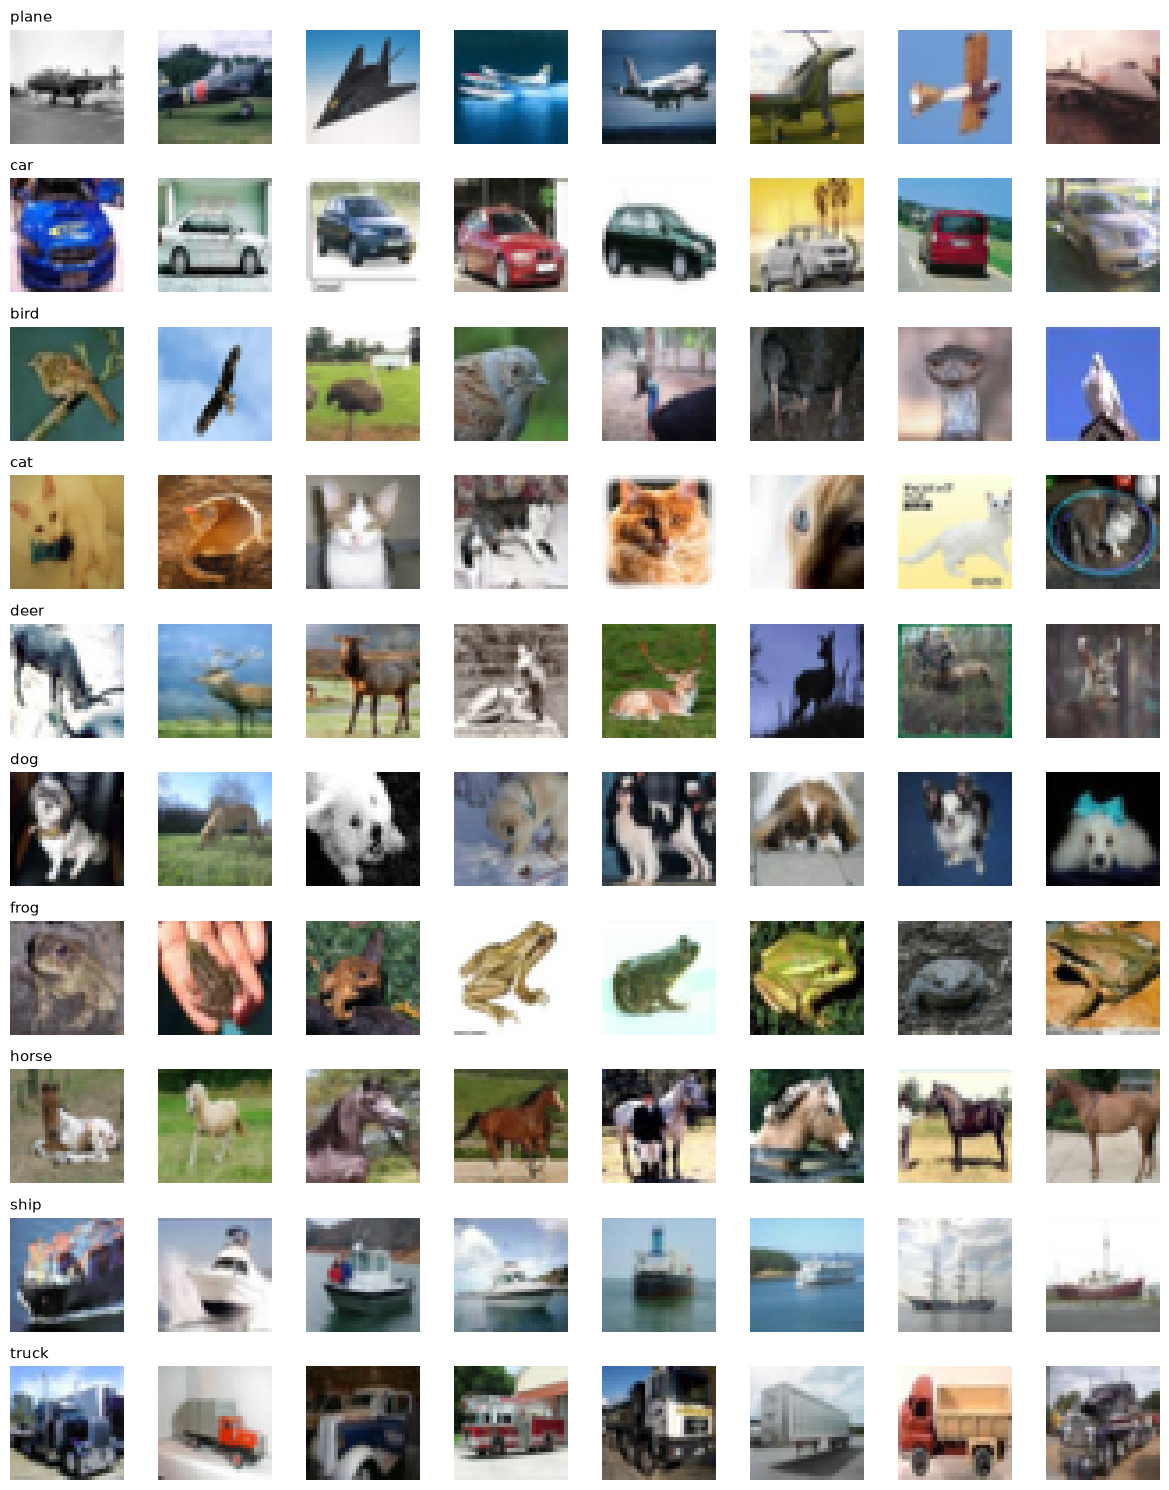

In [8]:
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(12, 15))
rng = np.random.RandomState(SEED)
for c in range(NUM_CLASSES):
    idx = rng.choice(np.where(y_all == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_all[i])
        axes[c, j].axis('off')
        if j == 0:
            axes[c, j].set_title(CLASSES[c], loc='left', fontsize=11)
plt.tight_layout()
plt.show()

### A2.3) Train / validation split (stratified)

The validation set is used to choose hyper-parameters (PCA / SVM). The 10,000 official test images are touched only for the final evaluation.

In [9]:
idx_train, idx_val = train_test_split(
    np.arange(len(y_all)), test_size=VAL_RATIO, stratify=y_all, random_state=SEED
)
print('train:', len(idx_train), '| val:', len(idx_val), '| test:', len(y_test))

y_train, y_val = y_all[idx_train], y_all[idx_val]

train: 45000 | val: 5000 | test: 10000


### A2.4) Normalization for PCA + SVM

1. **Flatten**: each `32x32x3` image becomes one vector of length 3072.
2. **Scale** pixels from 0-255 to 0-1.
3. **Standardize** each of the 3072 features to mean 0 and std 1. The scaler is fitted on the training subset only, then applied to validation and test (no leakage).

Standardizing matters because PCA looks for directions of maximum variance and the SVM's RBF kernel depends on distances.

In [10]:
def flatten01(X):
    return X.reshape(len(X), -1).astype(np.float32) / 255.0

# subset of the training split used for the SVM (idx_train is already shuffled)
idx_svm = idx_train if N_TRAIN_SVM is None else idx_train[:N_TRAIN_SVM]

X_svm_train = flatten01(X_all[idx_svm]);  y_svm_train = y_all[idx_svm]
X_val_flat = flatten01(X_all[idx_val])
X_test_flat = flatten01(X_test_raw)

print('Before scaling -> mean %.3f, std %.3f' % (X_svm_train.mean(), X_svm_train.std()))

scaler = StandardScaler().fit(X_svm_train)
X_svm_train = scaler.transform(X_svm_train)
X_val_flat = scaler.transform(X_val_flat)
X_test_flat = scaler.transform(X_test_flat)

print('After scaling  -> mean %.3f, std %.3f' % (X_svm_train.mean(), X_svm_train.std()))
print('SVM train:', X_svm_train.shape, '| val:', X_val_flat.shape, '| test:', X_test_flat.shape)

Before scaling -> mean 0.474, std 0.251
After scaling  -> mean -0.000, std 1.000
SVM train: (20000, 3072) | val: (5000, 3072) | test: (10000, 3072)


## A3. First train — without ResNet (PCA + SVM)

Pipeline: **flatten -> standardize -> PCA -> SVM (RBF kernel)**.

Raw pixels give 3072 features, many of them highly correlated. PCA keeps the directions with the most variance so the SVM works in a much smaller space.

### A3.1) Fit PCA and inspect explained variance

PCA fit: 1.4s
 50 components keep 83.9% of the variance
100 components keep 89.9% of the variance
200 components keep 94.5% of the variance


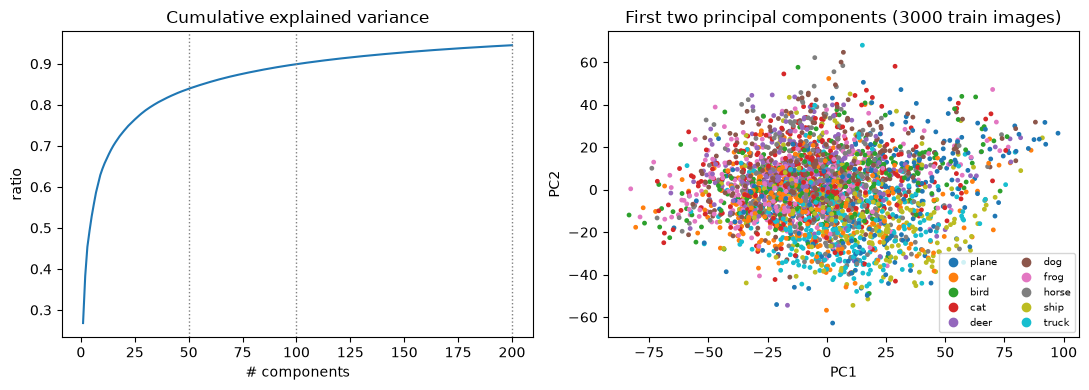

In [11]:
t0 = time.time()
pca = PCA(n_components=max(PCA_GRID), random_state=SEED).fit(X_svm_train)
print('PCA fit: %.1fs' % (time.time() - t0))

cum_var = np.cumsum(pca.explained_variance_ratio_)
for k in PCA_GRID:
    print('%3d components keep %.1f%% of the variance' % (k, 100 * cum_var[k - 1]))

# project everything once; smaller k is just a slice of the first k columns
Z_train_full = pca.transform(X_svm_train)
Z_val_full = pca.transform(X_val_flat)
Z_test_full = pca.transform(X_test_flat)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(cum_var) + 1), cum_var)
for k in PCA_GRID:
    ax[0].axvline(k, color='gray', ls=':', lw=1)
ax[0].set_title('Cumulative explained variance')
ax[0].set_xlabel('# components'); ax[0].set_ylabel('ratio')

sc = ax[1].scatter(Z_train_full[:3000, 0], Z_train_full[:3000, 1], c=y_svm_train[:3000], cmap='tab10', s=6)
ax[1].set_title('First two principal components (3000 train images)')
ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2')
ax[1].legend(handles=sc.legend_elements()[0], labels=CLASSES, fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

### A3.2) Pick the PCA size and SVM `C` on the validation set

A small grid search on a subset (`N_SWEEP` images) keeps this fast. Each setting is trained on the subset and scored on the validation split.

In [12]:
n_sweep = min(N_SWEEP, len(Z_train_full))
rows = []
for k in PCA_GRID:
    for C in C_GRID:
        t0 = time.time()
        clf = SVC(kernel='rbf', C=C, gamma='scale')
        clf.fit(Z_train_full[:n_sweep, :k], y_svm_train[:n_sweep])
        val_acc = clf.score(Z_val_full[:, :k], y_val)
        rows.append({'n_components': k, 'C': C, 'val_acc': val_acc, 'seconds': time.time() - t0})
        print('k=%3d  C=%-4s  val acc %.4f  (%.1fs)' % (k, C, val_acc, time.time() - t0))

sweep_df = pd.DataFrame(rows).sort_values('val_acc', ascending=False).reset_index(drop=True)
best_k = int(sweep_df.loc[0, 'n_components'])
best_C = float(sweep_df.loc[0, 'C'])
print('\nBest setting -> n_components=%d, C=%s' % (best_k, best_C))
sweep_df

k= 50  C=1     val acc 0.4578  (5.6s)
k= 50  C=10    val acc 0.4530  (6.7s)
k=100  C=1     val acc 0.4756  (8.4s)
k=100  C=10    val acc 0.4698  (9.4s)
k=200  C=1     val acc 0.4740  (10.7s)
k=200  C=10    val acc 0.4744  (12.9s)

Best setting -> n_components=100, C=1.0


,n_components,C,val_acc,seconds
0,100,1,0.4756,8.448254
1,200,10,0.4744,12.919853
2,200,1,0.4740,10.694758
3,100,10,0.4698,9.416467
4,50,1,0.4578,5.618325
5,50,10,0.4530,6.724056


### A3.3) Train the final SVM

Re-train with the best setting on the full SVM training subset (`N_TRAIN_SVM`).

In [13]:
t0 = time.time()
svm = SVC(kernel='rbf', C=best_C, gamma='scale')
svm.fit(Z_train_full[:, :best_k], y_svm_train)
svm_train_time = time.time() - t0

svm_val_acc = svm.score(Z_val_full[:, :best_k], y_val)
print('Final SVM trained on %d images in %.1fs' % (len(y_svm_train), svm_train_time))
print('Validation accuracy: %.4f' % svm_val_acc)

# predictions on the held-out test set (evaluated in section A4)
svm_pred = svm.predict(Z_test_full[:, :best_k])

Final SVM trained on 20000 images in 15.1s
Validation accuracy: 0.5002


## A4. Results (PCA + SVM)

Metrics on the 10,000 test images:
- **Accuracy**: share of images classified correctly
- **Precision**: of the images predicted as class *c*, how many really are *c*
- **Recall**: of the images that really are class *c*, how many were found
- **F1**: harmonic mean of precision and recall
- **Confusion matrix**: which classes get mixed up with which

### A4.1) Evaluation helpers

Part B defines the same helpers on its own, so both models are scored identically.

In [14]:
def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'accuracy': float(accuracy_score(y_true, y_pred)),
            'precision_macro': float(p), 'recall_macro': float(r), 'f1_macro': float(f)}

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)
    return pd.DataFrame({'precision': p, 'recall': r, 'f1': f, 'support': s}, index=CLASSES)

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, data, sub, fmt in [(axes[0], cm, 'counts', 'd'), (axes[1], cm_norm, 'row-normalized', '.2f')]:
        ax.imshow(data, interpolation='nearest', cmap='Blues')
        ax.set_title(title + ' (' + sub + ')')
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
        ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        thresh = data.max() / 2
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, format(data[i, j], fmt), ha='center', va='center', fontsize=8,
                        color='white' if data[i, j] > thresh else 'black')
    plt.tight_layout()
    plt.show()
    return cm

def show_misclassified(y_true, y_pred, n=12):
    wrong = np.where(y_true != y_pred)[0]
    pick = np.random.RandomState(SEED).choice(wrong, min(n, len(wrong)), replace=False)
    plt.figure(figsize=(12, 2.4 * ((len(pick) + 5) // 6)))
    for k, i in enumerate(pick):
        plt.subplot((len(pick) + 5) // 6, 6, k + 1)
        plt.imshow(X_test_raw[i])
        plt.title('true: %s\npred: %s' % (CLASSES[y_true[i]], CLASSES[y_pred[i]]), fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

### A4.2) Overall metrics + classification report

In [15]:
svm_metrics = compute_metrics(y_test, svm_pred)

print('PCA(%d) + SVM(C=%s) on the test set' % (best_k, best_C))
for k, v in svm_metrics.items():
    print('  %-16s %.4f' % (k, v))

print()
print(classification_report(y_test, svm_pred, target_names=CLASSES, digits=4))

PCA(100) + SVM(C=1.0) on the test set
  accuracy         0.4994
  precision_macro  0.4980
  recall_macro     0.4994
  f1_macro         0.4975

              precision    recall  f1-score   support

       plane     0.5821    0.5780    0.5800      1000
         car     0.6095    0.6010    0.6052      1000
        bird     0.3726    0.3540    0.3631      1000
         cat     0.3440    0.3330    0.3384      1000
        deer     0.4267    0.4220    0.4243      1000
         dog     0.4461    0.3970    0.4201      1000
        frog     0.4927    0.6060    0.5435      1000
       horse     0.5776    0.4950    0.5331      1000
        ship     0.5808    0.6470    0.6121      1000
       truck     0.5484    0.5610    0.5546      1000

    accuracy                         0.4994     10000
   macro avg     0.4980    0.4994    0.4975     10000
weighted avg     0.4980    0.4994    0.4975     10000



### A4.3) Confusion matrix

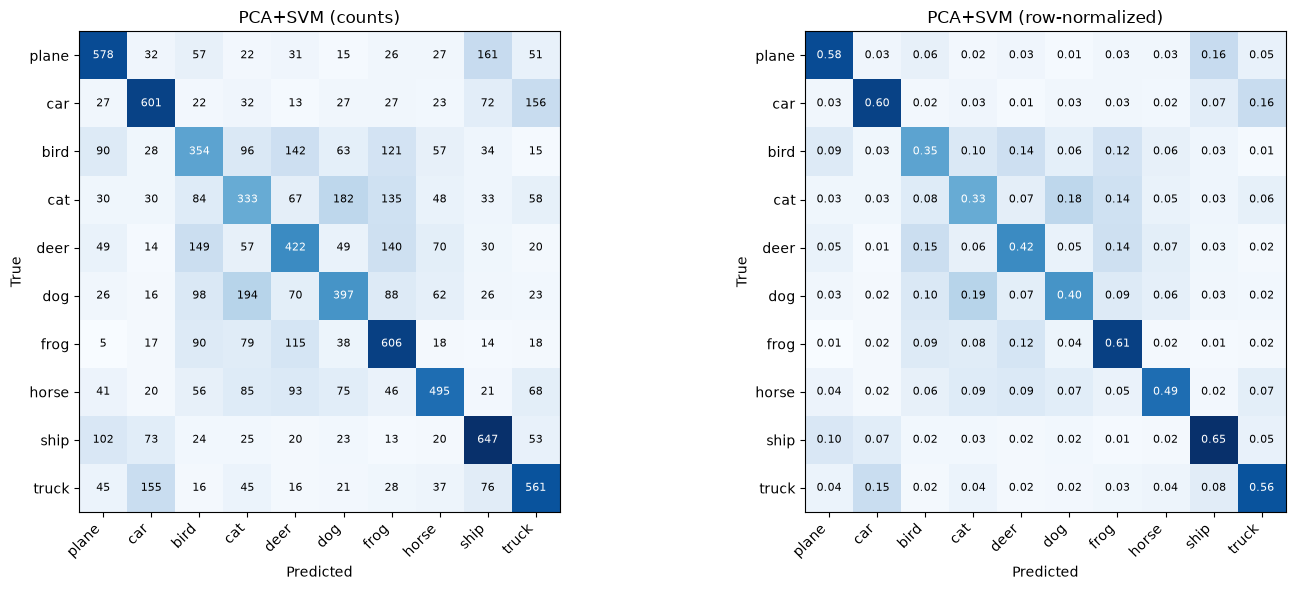

In [16]:
cm_svm = plot_confusion(y_test, svm_pred, 'PCA+SVM')

### A4.4) Per-class metrics and most-confused pairs

,precision,recall,f1,support
plane,0.5821,0.578,0.5800,1000
car,0.6095,0.601,0.6052,1000
bird,0.3726,0.354,0.3631,1000
cat,0.3440,0.333,0.3384,1000
deer,0.4267,0.422,0.4243,1000
dog,0.4461,0.397,0.4201,1000
frog,0.4927,0.606,0.5435,1000
horse,0.5776,0.495,0.5331,1000
ship,0.5808,0.647,0.6121,1000
truck,0.5484,0.561,0.5546,1000


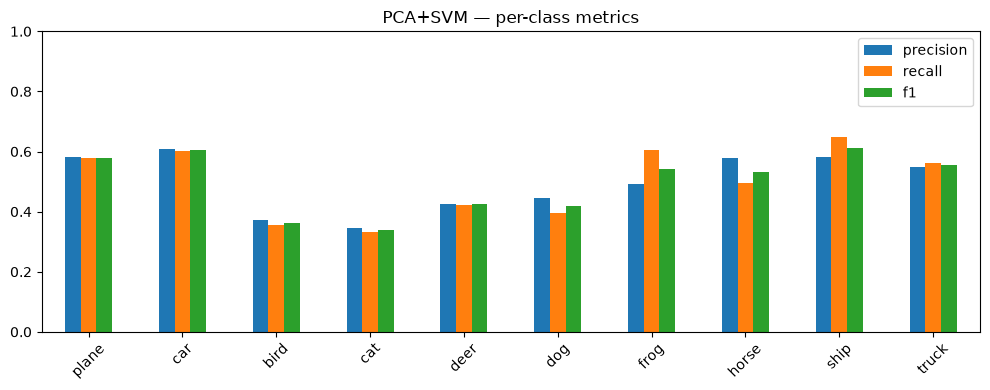

Most confused pairs (true -> predicted):
  dog    -> cat    : 194 images
  cat    -> dog    : 182 images
  plane  -> ship   : 161 images
  car    -> truck  : 156 images
  truck  -> car    : 155 images


In [17]:
svm_pc = per_class_table(y_test, svm_pred)
display(svm_pc.round(4))

svm_pc[['precision', 'recall', 'f1']].plot(kind='bar', figsize=(10, 4), title='PCA+SVM — per-class metrics')
plt.ylim(0, 1); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

off = cm_svm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
print('Most confused pairs (true -> predicted):')
for i, j in top:
    print('  %-6s -> %-6s : %d images' % (CLASSES[i], CLASSES[j], off[i, j]))

### A4.5) Misclassified examples

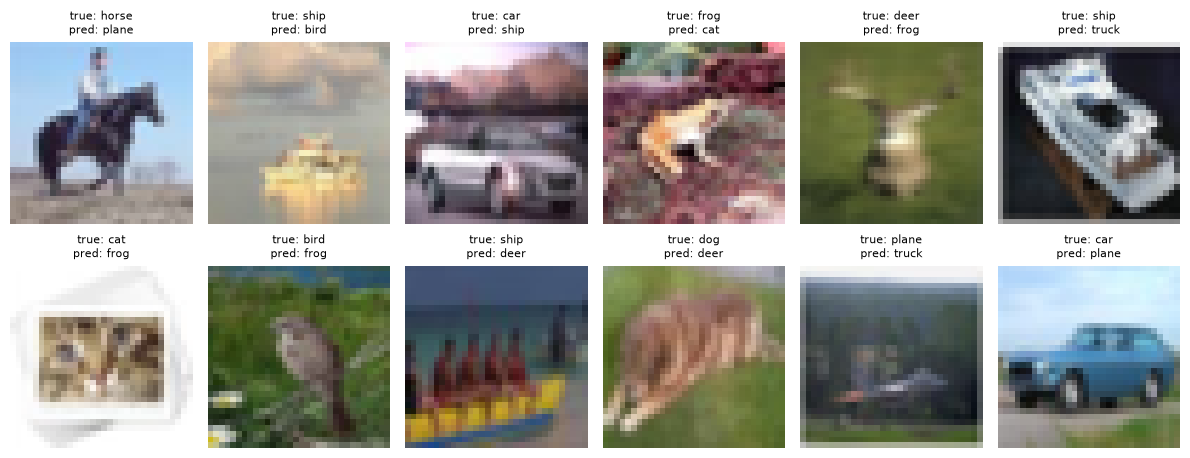

In [18]:
show_misclassified(y_test, svm_pred)

### A4.6) Package the Part A result

Part C reads only this one variable from Part A.

In [19]:
svm_result = {
    'detail': 'PCA(%d) + RBF-SVM(C=%s)' % (best_k, best_C),
    'train_time_s': float(svm_train_time),
    'metrics': svm_metrics,
    'per_class': svm_pc,
    'y_true': np.array(y_test),
    'y_pred': np.array(svm_pred),
}
print('Part A done:', svm_result['detail'], '| test accuracy %.4f' % svm_metrics['accuracy'])

Part A done: PCA(100) + RBF-SVM(C=1.0) | test accuracy 0.4994


---
# PART B — ResNet18 (deep learning)

Sections: B1 Setup, B2 Data manipulation, B3 Second train with ResNet18, B4 Results.

Part B starts from scratch: it re-imports, re-loads the data and re-creates the split. It does not use anything from Part A.

## B1. Setup

### B1.1) Imports

Part B needs `torch` and `torchvision` (plus `numpy`, `pandas`, `matplotlib`, `pillow` and `scikit-learn` for the split and the metrics). It does not use PCA or SVM.

In [20]:
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models



warnings.filterwarnings('ignore')
print('torch:', torch.__version__)
print('torchvision:', __import__('torchvision').__version__)

torch: 2.14.0
torchvision: 0.29.0


### B1.2) Device

We use `cuda` if available, else `mps` (Apple Silicon), else `cpu`.

In [21]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

device = get_device()
device

device(type='mps')

### B1.3) Configuration

Everything we want to tune is in here.

- `IMG_SIZE`: CIFAR images are 32x32. Upscaling helps the ImageNet-pretrained ResNet18 (`224` is the most accurate but slowest; `64`-`128` is a good trade-off).
- `SEED` and `VAL_RATIO` must match the same two values in Part A so both use the identical split.

In [22]:
OUT_DIR = Path('models')                  # model weights + class names
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- ResNet18 ---
USE_PRETRAINED = True    # ImageNet weights
IMG_SIZE = 128
BATCH = 128
NUM_WORKERS = 0
EPOCHS_1 = 3             # phase 1: train the new head only
EPOCHS_2 = 7             # phase 2: fine-tune the whole network
LR_HEAD = 1e-3
LR_FT = 1e-4

print('Device:', device)
print('Classes:', CLASSES)

Device: mps
Classes: ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### B1.4) Reproducibility

In [23]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

## B2. Data manipulation

We load CIFAR-10 and prepare it for ResNet18:

| Pipeline | Input | Normalization |
|---|---|---|
| ResNet18 | image tensor `[3, H, W]` | scale to [0, 1], then ImageNet mean / std (what the pretrained weights expect) |

### B2.1) Load raw CIFAR-10

In [24]:
def load_batch(path):
    with open(path, 'rb') as f:
        d = pickle.load(f, encoding='bytes')
    # stored as (N, 3072) = 1024 R + 1024 G + 1024 B  ->  (N, 32, 32, 3)
    X = d[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(d[b'labels'])
    return np.ascontiguousarray(X), y

assert CIFAR_DIR.is_dir(), 'Folder not found: %s (set CIFAR_DIR in the config cell)' % CIFAR_DIR

parts = [load_batch(CIFAR_DIR / ('data_batch_%d' % i)) for i in range(1, 6)]
X_all = np.concatenate([p[0] for p in parts])      # (50000, 32, 32, 3) uint8
y_all = np.concatenate([p[1] for p in parts])      # (50000,)
X_test_raw, y_test = load_batch(CIFAR_DIR / 'test_batch')   # (10000, 32, 32, 3), (10000,)

with open(CIFAR_DIR / 'batches.meta', 'rb') as f:
    meta = pickle.load(f, encoding='bytes')
print('Label names in batches.meta:', [n.decode() for n in meta[b'label_names']])

print('Train images:', X_all.shape, X_all.dtype)
print('Test images :', X_test_raw.shape)
print('Pixel range :', X_all.min(), '-', X_all.max())
print('Images per class (train):', np.bincount(y_all).tolist())

Label names in batches.meta: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train images: (50000, 32, 32, 3) uint8
Test images : (10000, 32, 32, 3)
Pixel range : 0 - 255
Images per class (train): [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]


### B2.2) Visual sanity-check

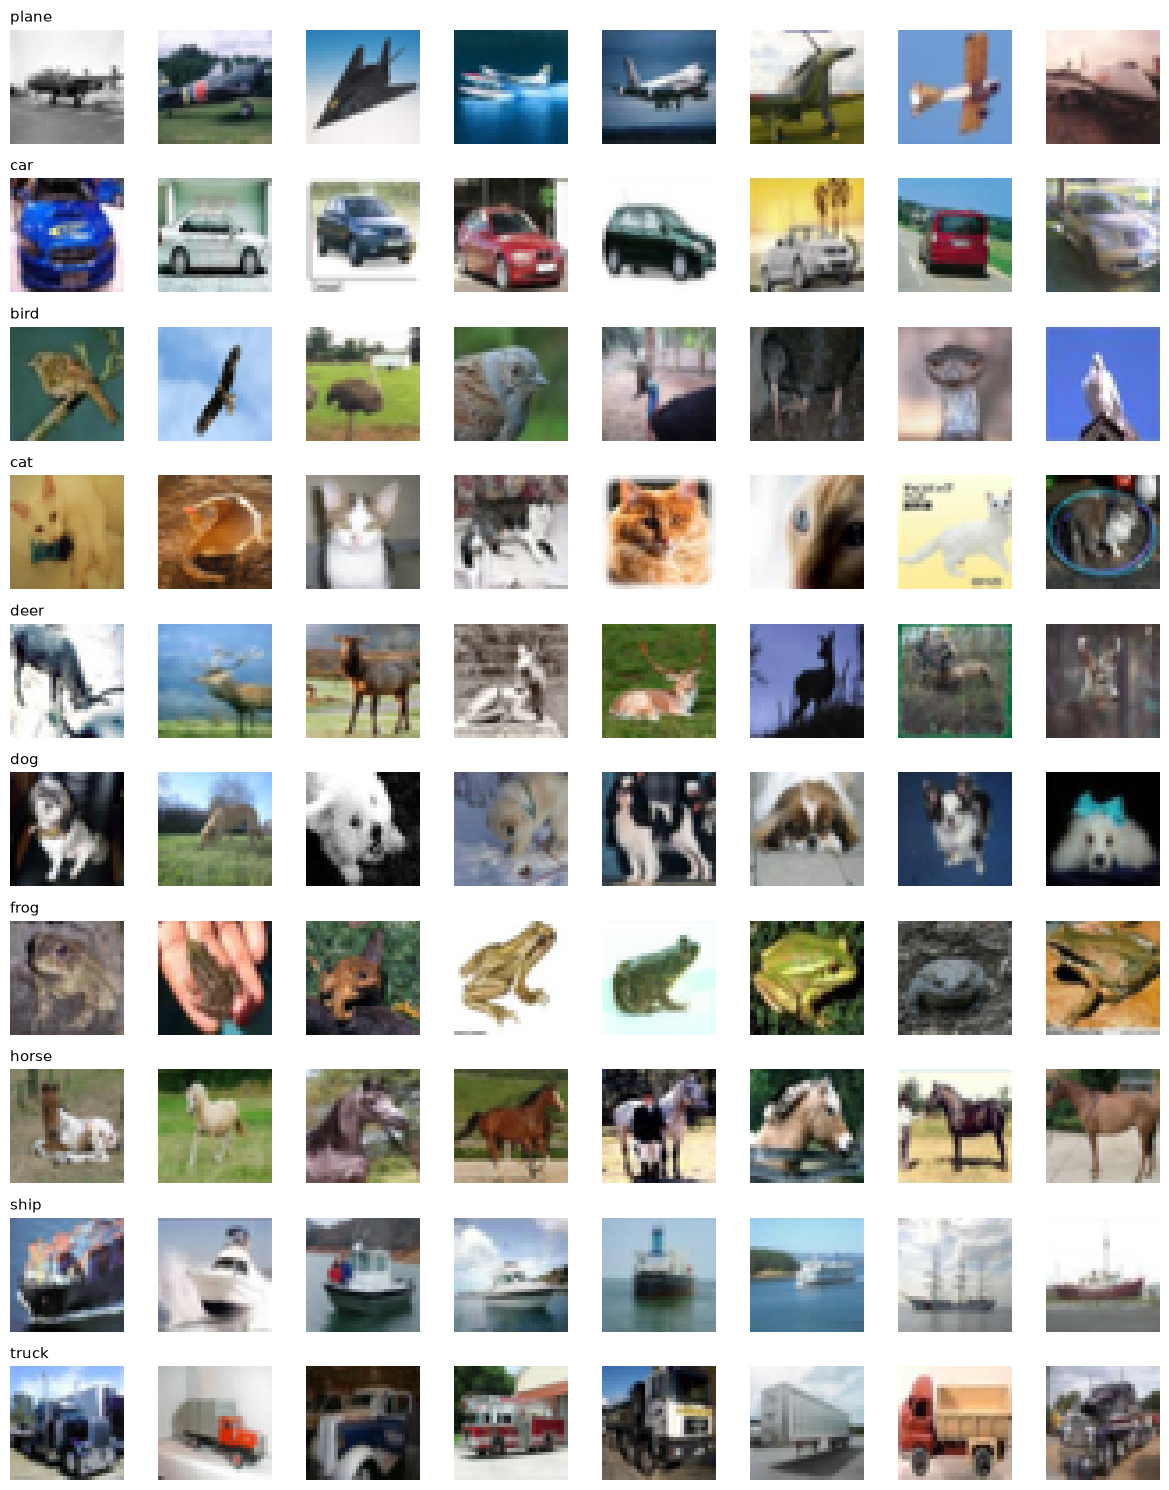

In [25]:
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(12, 15))
rng = np.random.RandomState(SEED)
for c in range(NUM_CLASSES):
    idx = rng.choice(np.where(y_all == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_all[i])
        axes[c, j].axis('off')
        if j == 0:
            axes[c, j].set_title(CLASSES[c], loc='left', fontsize=11)
plt.tight_layout()
plt.show()

### B2.3) Train / validation split (stratified)

The validation set is used to choose the best ResNet checkpoint. The 10,000 official test images are touched only for the final evaluation.

In [26]:
idx_train, idx_val = train_test_split(
    np.arange(len(y_all)), test_size=VAL_RATIO, stratify=y_all, random_state=SEED
)
print('train:', len(idx_train), '| val:', len(idx_val), '| test:', len(y_test))

y_train, y_val = y_all[idx_train], y_all[idx_val]

train: 45000 | val: 5000 | test: 10000


### B2.4) Normalization + augmentation for ResNet18

The ImageNet-pretrained weights expect:
- mean = (0.485, 0.456, 0.406)
- std  = (0.229, 0.224, 0.225)

Training images get light augmentation (random crop with padding + horizontal flip). Validation / test images are only resized and normalized.

In [27]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_tfms = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class CifarArrayDataset(Dataset):
    # wraps the uint8 arrays loaded from cifar-10-batches-py
    def __init__(self, X, y, transform=None):
        self.X, self.y, self.transform = X, y, transform
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = Image.fromarray(self.X[i])
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.y[i])

train_ds = CifarArrayDataset(X_all[idx_train], y_all[idx_train], train_tfms)   # with augmentation
val_ds = CifarArrayDataset(X_all[idx_val], y_all[idx_val], eval_tfms)          # no augmentation
test_ds = CifarArrayDataset(X_test_raw, y_test, eval_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS)

print('ResNet train / val / test:', len(train_ds), len(val_ds), len(test_ds))

ResNet train / val / test: 45000 5000 10000


Batch tensor: (128, 3, 128, 128) | mean -0.17, std 1.18


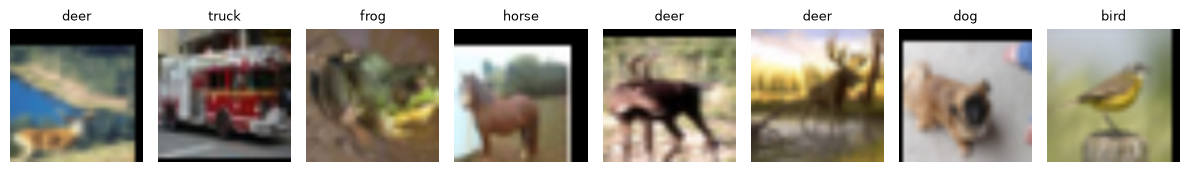

In [28]:
def denorm(img_t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return torch.clamp(img_t.cpu() * std + mean, 0, 1)

images, labels = next(iter(train_loader))
print('Batch tensor:', tuple(images.shape), '| mean %.2f, std %.2f' % (images.mean(), images.std()))

plt.figure(figsize=(12, 3.5))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(denorm(images[i]).permute(1, 2, 0))
    plt.title(CLASSES[labels[i].item()], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## B3. Second train with ResNet18

We use **transfer learning** with a ResNet18 pretrained on ImageNet:

- **Phase 1** — freeze the backbone, train only the new final layer (`fc`, 10 outputs).
- **Phase 2** — unfreeze everything and fine-tune with a lower learning rate and a cosine schedule.

The checkpoint with the best **validation** accuracy across both phases is kept.

### B3.1) Build the model

In [29]:
seed_everything(SEED)

def build_resnet18(num_classes, pretrained=True):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, num_classes)   # new head for 10 classes
    return m

model = build_resnet18(NUM_CLASSES, USE_PRETRAINED).to(device)

total_params = sum(p.numel() for p in model.parameters())
print('ResNet18 parameters: %.2fM' % (total_params / 1e6))
print('Final layer:', model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/kangvc95/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%

ResNet18 parameters: 11.18M
Final layer: Linear(in_features=512, out_features=10, bias=True)


### B3.2) Training utilities

In [30]:
criterion = nn.CrossEntropyLoss()
history = []                       # one dict per epoch (both phases)
best_val_acc = 0.0
BEST_PATH = OUT_DIR / 'resnet18_best.pt'

def run_epoch(model, loader, criterion, optimizer=None, freeze_bn=False):
    training = optimizer is not None
    model.train(training)
    if training and freeze_bn:     # keep BatchNorm statistics of the frozen backbone
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

def run_phase(name, epochs, optimizer, scheduler=None, freeze_bn=False):
    global best_val_acc
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, freeze_bn)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if scheduler is not None:
            scheduler.step()
        history.append({'phase': name, 'epoch': len(history) + 1, 'train_loss': tr_loss,
                        'train_acc': tr_acc, 'val_loss': va_loss, 'val_acc': va_acc})
        flag = ''
        if va_acc > best_val_acc:
            best_val_acc = va_acc
            torch.save(model.state_dict(), BEST_PATH)
            flag = '  <- best'
        print('[%s][%d/%d] train loss %.4f acc %.4f | val loss %.4f acc %.4f | %.1fs%s' %
              (name, epoch, epochs, tr_loss, tr_acc, va_loss, va_acc, time.time() - t0, flag))

### B3.3) Phase 1: train the head (backbone frozen)

In [31]:
resnet_t0 = time.time()

for name, p in model.named_parameters():
    p.requires_grad = name.startswith('fc.')

opt1 = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR_HEAD)
run_phase('Phase1', EPOCHS_1, opt1, freeze_bn=True)
print('Best val acc so far: %.4f' % best_val_acc)

[Phase1][1/3] train loss 0.7503 acc 0.7547 | val loss 0.5043 acc 0.8244 | 114.9s  <- best
[Phase1][2/3] train loss 0.5356 acc 0.8186 | val loss 0.4811 acc 0.8390 | 112.9s  <- best
[Phase1][3/3] train loss 0.5097 acc 0.8246 | val loss 0.4720 acc 0.8418 | 102.8s  <- best
Best val acc so far: 0.8418


### B3.4) Phase 2: fine-tune the whole network

In [32]:
for p in model.parameters():
    p.requires_grad = True

opt2 = optim.AdamW(model.parameters(), lr=LR_FT, weight_decay=1e-4)
sched2 = optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=EPOCHS_2)
run_phase('Phase2', EPOCHS_2, opt2, scheduler=sched2)

resnet_train_time = time.time() - resnet_t0
print('Best val acc (final): %.4f | total training time: %.1f min' % (best_val_acc, resnet_train_time / 60))

[Phase2][1/7] train loss 0.3383 acc 0.8857 | val loss 0.2061 acc 0.9314 | 318.3s  <- best


KeyboardInterrupt: 

## B4. Results (ResNet18)

### B4.1) Evaluation helpers

Part A defines the same helpers on its own, so both models are scored identically.

In [ ]:
def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'accuracy': float(accuracy_score(y_true, y_pred)),
            'precision_macro': float(p), 'recall_macro': float(r), 'f1_macro': float(f)}

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)
    return pd.DataFrame({'precision': p, 'recall': r, 'f1': f, 'support': s}, index=CLASSES)

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, data, sub, fmt in [(axes[0], cm, 'counts', 'd'), (axes[1], cm_norm, 'row-normalized', '.2f')]:
        ax.imshow(data, interpolation='nearest', cmap='Blues')
        ax.set_title(title + ' (' + sub + ')')
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
        ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        thresh = data.max() / 2
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, format(data[i, j], fmt), ha='center', va='center', fontsize=8,
                        color='white' if data[i, j] > thresh else 'black')
    plt.tight_layout()
    plt.show()
    return cm

def show_misclassified(y_true, y_pred, n=12):
    wrong = np.where(y_true != y_pred)[0]
    pick = np.random.RandomState(SEED).choice(wrong, min(n, len(wrong)), replace=False)
    plt.figure(figsize=(12, 2.4 * ((len(pick) + 5) // 6)))
    for k, i in enumerate(pick):
        plt.subplot((len(pick) + 5) // 6, 6, k + 1)
        plt.imshow(X_test_raw[i])
        plt.title('true: %s\npred: %s' % (CLASSES[y_true[i]], CLASSES[y_pred[i]]), fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

### B4.2) Training curves

In [ ]:
hist = pd.DataFrame(history)
display(hist.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (tr, va, title) in zip(ax, [('train_acc', 'val_acc', 'Accuracy'), ('train_loss', 'val_loss', 'Loss')]):
    a.plot(hist['epoch'], hist[tr], marker='o', label='train')
    a.plot(hist['epoch'], hist[va], marker='o', label='val')
    a.axvline(EPOCHS_1 + 0.5, color='gray', ls='--', lw=1, label='phase 1 | phase 2')
    a.set_title(title); a.set_xlabel('epoch'); a.legend()
plt.tight_layout()
plt.show()

### B4.3) Test evaluation with the best checkpoint

In [ ]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

model.load_state_dict(torch.load(BEST_PATH, map_location='cpu'))
model = model.to(device)
print('Loaded best weights:', BEST_PATH)

y_true_r, resnet_pred = predict_all(model, test_loader)
assert (y_true_r == y_test).all()

resnet_metrics = compute_metrics(y_test, resnet_pred)

print('ResNet18 on the test set')
for k, v in resnet_metrics.items():
    print('  %-16s %.4f' % (k, v))

print()
print(classification_report(y_test, resnet_pred, target_names=CLASSES, digits=4))

### B4.4) Confusion matrix

In [ ]:
cm_resnet = plot_confusion(y_test, resnet_pred, 'ResNet18')

### B4.5) Per-class metrics, most-confused pairs, misclassified examples

In [ ]:
resnet_pc = per_class_table(y_test, resnet_pred)
display(resnet_pc.round(4))

resnet_pc[['precision', 'recall', 'f1']].plot(kind='bar', figsize=(10, 4), title='ResNet18 — per-class metrics')
plt.ylim(0, 1); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

off = cm_resnet.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
print('Most confused pairs (true -> predicted):')
for i, j in top:
    print('  %-6s -> %-6s : %d images' % (CLASSES[i], CLASSES[j], off[i, j]))

show_misclassified(y_test, resnet_pred)

### B4.6) Save artifacts

In [ ]:
torch.save(model.state_dict(), OUT_DIR / 'resnet18_cifar10.pt')
with open(OUT_DIR / 'class_names.json', 'w', encoding='utf-8') as f:
    json.dump(CLASSES, f)
print('Saved:', OUT_DIR / 'resnet18_cifar10.pt')
print('Saved:', OUT_DIR / 'class_names.json')

### B4.7) Package the Part B result

Part C reads only this one variable from Part B.

In [ ]:
resnet_result = {
    'detail': 'ResNet18 %s, %dpx, %d+%d epochs' %
              ('pretrained' if USE_PRETRAINED else 'from scratch', IMG_SIZE, EPOCHS_1, EPOCHS_2),
    'train_time_s': float(resnet_train_time),
    'metrics': resnet_metrics,
    'per_class': resnet_pc,
    'y_true': np.array(y_test),
    'y_pred': np.array(resnet_pred),
}
print('Part B done:', resnet_result['detail'], '| test accuracy %.4f' % resnet_metrics['accuracy'])

---
# PART C — Compare

We will compare best of the first train (without ResNet) and best of the second train (with ResNet). Both models are scored on the **same 10,000 test images** with the same metric code.

- First train: the best PCA + SVM setting chosen on the validation set (section A3.2).
- Second train: the best ResNet18 checkpoint chosen on the validation set (section B3).

Part C only uses `svm_result` (from Part A) and `resnet_result` (from Part B), so run both parts first.

## C1. Collect the two results

In [ ]:
results = {'PCA+SVM': svm_result, 'ResNet18': resnet_result}

# both models must have been scored on the same test images in the same order
assert (results['PCA+SVM']['y_true'] == results['ResNet18']['y_true']).all()
y_cmp = results['PCA+SVM']['y_true']
print('Comparing:', list(results), '| test images:', len(y_cmp))

## C2. Summary table

In [ ]:
summary = pd.DataFrame({
    name: {'setup': r['detail'],
           'accuracy': r['metrics']['accuracy'],
           'precision (macro)': r['metrics']['precision_macro'],
           'recall (macro)': r['metrics']['recall_macro'],
           'F1 (macro)': r['metrics']['f1_macro'],
           'train time (min)': r['train_time_s'] / 60}
    for name, r in results.items()
}).T
for c in summary.columns[1:]:
    summary[c] = summary[c].astype(float).round(4)
display(summary)

acc_svm = results['PCA+SVM']['metrics']['accuracy']
acc_res = results['ResNet18']['metrics']['accuracy']
gain = acc_res - acc_svm
winner = 'ResNet18' if gain > 0 else 'PCA+SVM'
print('Test accuracy: PCA+SVM %.2f%%  vs  ResNet18 %.2f%%  ->  %s wins by %.2f points' %
      (100 * acc_svm, 100 * acc_res, winner, 100 * abs(gain)))

## C3. Overall metrics side by side

In [ ]:
metric_keys = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1']
x = np.arange(len(metric_keys)); w = 0.38

plt.figure(figsize=(8, 4))
for off_i, name in enumerate(results):
    vals = [results[name]['metrics'][k] for k in metric_keys]
    bars = plt.bar(x + (off_i - 0.5) * w, vals, w, label=name)
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.01, '%.3f' % v, ha='center', fontsize=8)
plt.xticks(x, metric_labels); plt.ylim(0, 1.1)
plt.title('Test metrics (macro-averaged)'); plt.legend()
plt.tight_layout(); plt.show()

## C4. Per-class F1 and confusion matrices

In [ ]:
f1_cmp = pd.DataFrame({'PCA+SVM': results['PCA+SVM']['per_class']['f1'],
                       'ResNet18': results['ResNet18']['per_class']['f1']})
f1_cmp['improvement'] = f1_cmp['ResNet18'] - f1_cmp['PCA+SVM']
display(f1_cmp.round(4))

f1_cmp[['PCA+SVM', 'ResNet18']].plot(kind='bar', figsize=(10, 4), title='Per-class F1')
plt.ylim(0, 1); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, results):
    cm = confusion_matrix(y_cmp, results[name]['y_pred'], labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_title('%s (row-normalized, acc %.3f)' % (name, results[name]['metrics']['accuracy']))
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, '%.2f' % cmn[i, j], ha='center', va='center', fontsize=7,
                    color='white' if cmn[i, j] > 0.5 else 'black')
plt.tight_layout(); plt.show()

best_gain = f1_cmp['improvement'].idxmax()
least_gain = f1_cmp['improvement'].idxmin()
print('Biggest F1 gain from ResNet18: %s (%+.3f)' % (best_gain, f1_cmp.loc[best_gain, 'improvement']))
print('Smallest F1 gain             : %s (%+.3f)' % (least_gain, f1_cmp.loc[least_gain, 'improvement']))